<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Setup and Dataset Generation
We will import the required libraries and generate a synthetic tabular dataset of 500 clinical records for diabetes prediction.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Generate a synthetic diabetes dataset with 500 samples and 8 clinical features
from sklearn.datasets import make_classification
X, y = make_classification(
    n_samples=500,
    n_features=8,
    n_informative=6,
    n_redundant=2,
    random_state=42,
    class_sep=0.8
)

# Split into Train, Validation, and Test sets (60%, 20%, 20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (300, 8)
Validation set shape: (100, 8)
Test set shape: (100, 8)


### Task 1: Train a Deliberately Large Baseline MLP
We will design a relatively large network that easily overfits our small dataset.

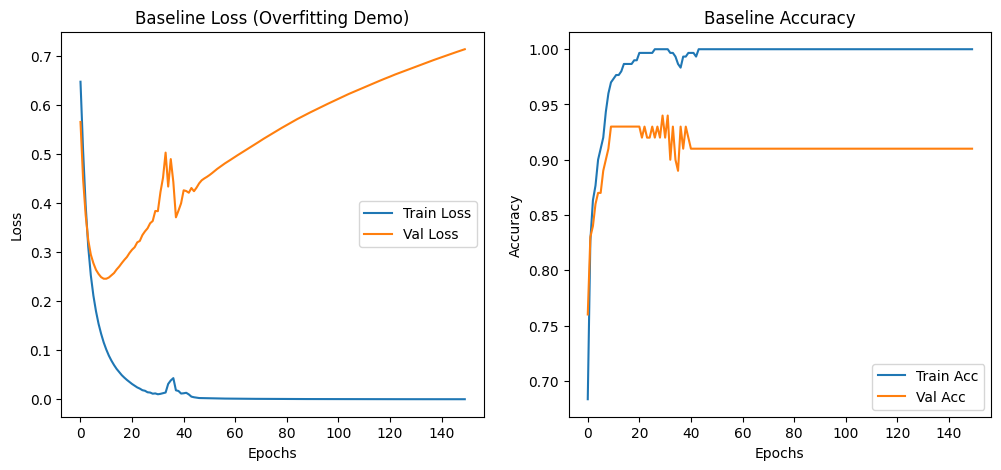

In [3]:
def get_baseline_model():
    model = keras.Sequential([
        layers.Input(shape=(8,)),
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

baseline_model = get_baseline_model()
history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=0
)

# Plot baseline training history to visualize overfitting
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['loss'], label='Train Loss')
plt.plot(history_baseline.history['val_loss'], label='Val Loss')
plt.title('Baseline Loss (Overfitting Demo)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history['accuracy'], label='Train Acc')
plt.plot(history_baseline.history['val_accuracy'], label='Val Acc')
plt.title('Baseline Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Tasks 2, 3, 4 & 5: Train Regularized Models & Tabulate Results
We will create a helper function to compile, train, evaluate models, and store the metrics for final comparison.

In [4]:
results = {}

def record_metrics(name, model, history):
    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    gap = train_acc - test_acc
    results[name] = {
        'Train Acc': train_acc,
        'Test Acc': test_acc,
        'Gap (Train-Test)': gap
    }
    print(f"{name:20s} -> Train Acc: {train_acc:.4f} | Test Acc: {test_acc:.4f} | Gap: {gap:.4f}")

# 1. Record Baseline
record_metrics('Baseline', baseline_model, history_baseline)

# 2. Retrain with L2 regularization at three lambda values: 0.001, 0.01, 0.1
for l2_val in [0.001, 0.01, 0.1]:
    model_l2 = keras.Sequential([
        layers.Input(shape=(8,)),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(l2_val)),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(l2_val)),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(l2_val)),
        layers.Dense(1, activation='sigmoid')
    ])
    model_l2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    h_l2 = model_l2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=150, batch_size=32, verbose=0)
    record_metrics(f'L2 (lambda={l2_val})', model_l2, h_l2)

# 3. Retrain with dropout at rates 0.2, 0.3, and 0.5
for drop_rate in [0.2, 0.3, 0.5]:
    model_drop = keras.Sequential([
        layers.Input(shape=(8,)),
        layers.Dense(256, activation='relu'),
        layers.Dropout(drop_rate),
        layers.Dense(128, activation='relu'),
        layers.Dropout(drop_rate),
        layers.Dense(64, activation='relu'),
        layers.Dropout(drop_rate),
        layers.Dense(1, activation='sigmoid')
    ])
    model_drop.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    h_drop = model_drop.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=150, batch_size=32, verbose=0)
    record_metrics(f'Dropout (rate={drop_rate})', model_drop, h_drop)

# 4. Retrain with Early Stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)
model_es = get_baseline_model()
h_es = model_es.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
record_metrics('Early Stopping', model_es, h_es)

Baseline             -> Train Acc: 1.0000 | Test Acc: 0.9000 | Gap: 0.1000
L2 (lambda=0.001)    -> Train Acc: 1.0000 | Test Acc: 0.9000 | Gap: 0.1000
L2 (lambda=0.01)     -> Train Acc: 0.9967 | Test Acc: 0.8800 | Gap: 0.1167
L2 (lambda=0.1)      -> Train Acc: 0.8800 | Test Acc: 0.8100 | Gap: 0.0700
Dropout (rate=0.2)   -> Train Acc: 1.0000 | Test Acc: 0.9100 | Gap: 0.0900
Dropout (rate=0.3)   -> Train Acc: 1.0000 | Test Acc: 0.9000 | Gap: 0.1000
Dropout (rate=0.5)   -> Train Acc: 1.0000 | Test Acc: 0.8900 | Gap: 0.1100
Early Stopping       -> Train Acc: 0.9733 | Test Acc: 0.8800 | Gap: 0.0933


### Task 5: Tabulate and Compare Final Metrics

In [5]:
import pandas as pd

# Construct and display the comparison table
df_results = pd.DataFrame(results).T
display(df_results)

,Train Acc,Test Acc,Gap (Train-Test)
Baseline,1.000000,0.90,0.100000
L2 (lambda=0.001),1.000000,0.90,0.100000
L2 (lambda=0.01),0.996667,0.88,0.116667
L2 (lambda=0.1),0.880000,0.81,0.070000
Dropout (rate=0.2),1.000000,0.91,0.090000
Dropout (rate=0.3),1.000000,0.90,0.100000
Dropout (rate=0.5),1.000000,0.89,0.110000
Early Stopping,0.973333,0.88,0.093333
